1. Design FIR Low pass filter having cutoff frequency 3 KHz, N=31; Sampling frequency=10 KHz
2. Design FIR High pass filter having cutoff frequency 3 KHz, N=31; Sampling frequency=10 KHz
3. Design FIR Band pass filter having cutoff frequency( 3 KHz, 6 KHz) N=31; Sampling frequency=10 KHz
4. Design FIR Band stop filter having cutoff frequency( 3 KHz, 6 KHz) N=31; Sampling frequency=10 KHz

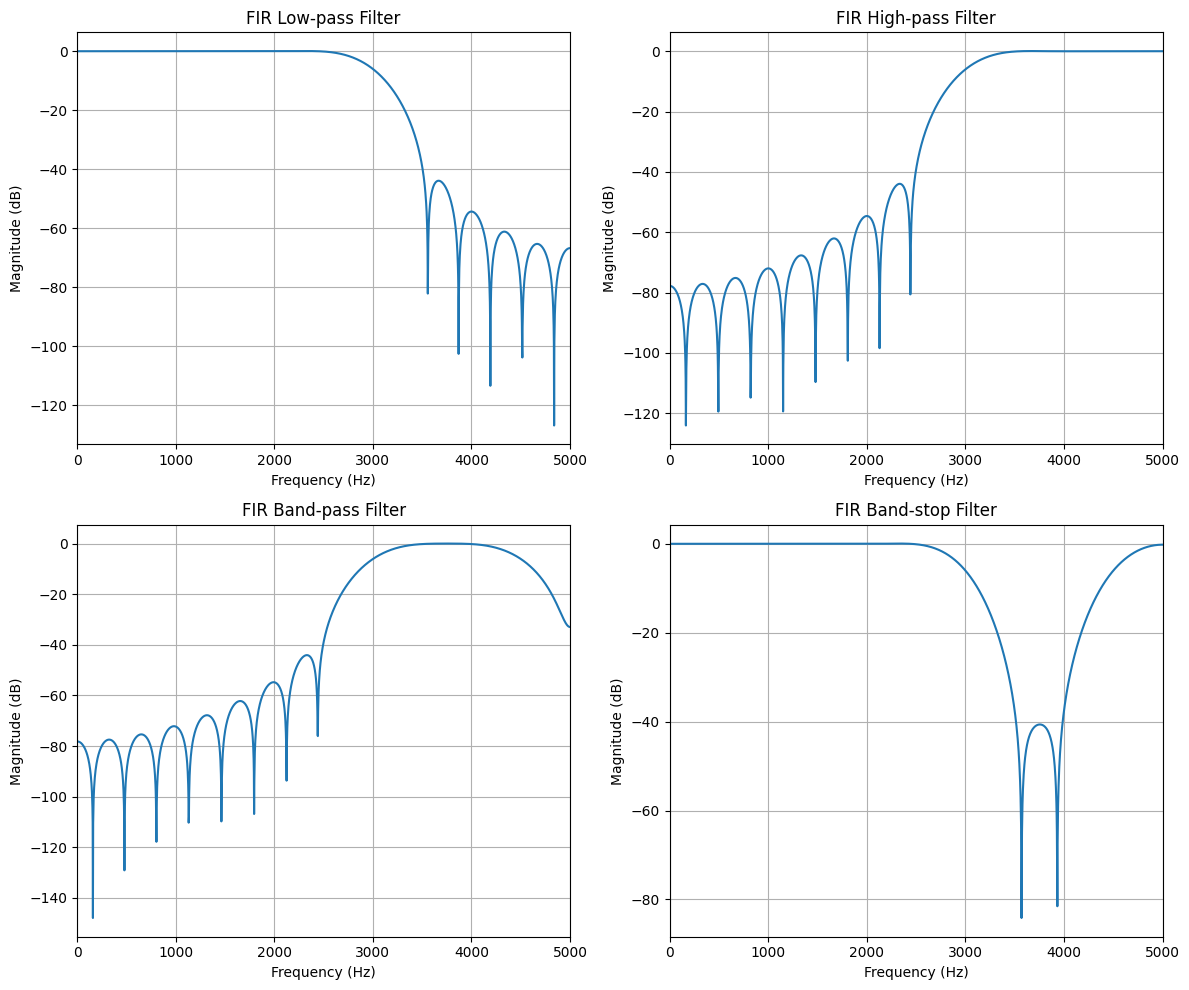


 FIR Low-pass Filter
Filter coefficients:
[ 0.00000e+00  2.36000e-04 -6.22000e-04 -1.48900e-03  4.55400e-03
 -0.00000e+00 -1.16230e-02  1.04730e-02  1.47630e-02 -3.30280e-02
  0.00000e+00  6.31700e-02 -5.64180e-02 -8.95170e-02  2.99462e-01
  6.00077e-01  2.99462e-01 -8.95170e-02 -5.64180e-02  6.31700e-02
  0.00000e+00 -3.30280e-02  1.47630e-02  1.04730e-02 -1.16230e-02
 -0.00000e+00  4.55400e-03 -1.48900e-03 -6.22000e-04  2.36000e-04
  0.00000e+00]

 FIR High-pass Filter
Filter coefficients:
[ 0.00000e+00 -2.36000e-04  6.22000e-04  1.48800e-03 -4.55100e-03
 -0.00000e+00  1.16160e-02 -1.04660e-02 -1.47540e-02  3.30080e-02
  0.00000e+00 -6.31330e-02  5.63850e-02  8.94640e-02 -2.99285e-01
  3.99816e-01 -2.99285e-01  8.94640e-02  5.63850e-02 -6.31330e-02
  0.00000e+00  3.30080e-02 -1.47540e-02 -1.04660e-02  1.16160e-02
 -0.00000e+00 -4.55100e-03  1.48800e-03  6.22000e-04 -2.36000e-04
  0.00000e+00]

 FIR Band-pass Filter
Filter coefficients:
[-0.00000e+00  0.00000e+00 -2.32000e-04  2.9500

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

# Step 1: Define filter parameters
Fs = 10000       # Sampling frequency = 10 kHz
Fc = 3000        # Cutoff frequency = 3 kHz
N = 31           # Number of filter taps
window_type = 'hann'

# Step 2: Design the four FIR filters

# 1. FIR Low-pass filter
b_low = firwin(
    numtaps=N,
    cutoff=Fc,
    window=window_type,
    pass_zero='lowpass',
    fs=Fs
)

# 2. FIR High-pass filter
b_high = firwin(
    numtaps=N,
    cutoff=Fc,
    window=window_type,
    pass_zero='highpass',
    fs=Fs
)

# Band edges must be below the Nyquist frequency (5000 Hz)
band_edges = [3000, 4500]

# 3. FIR Band-pass filter
b_bandpass = firwin(
    numtaps=N,
    cutoff=band_edges,
    window=window_type,
    pass_zero='bandpass',
    fs=Fs
)

# 4. FIR Band-stop filter
b_bandstop = firwin(
    numtaps=N,
    cutoff=band_edges,
    window=window_type,
    pass_zero='bandstop',
    fs=Fs
)

# Step 3: Calculate and plot frequency responses
filters = [
    ("FIR Low-pass Filter", b_low),
    ("FIR High-pass Filter", b_high),
    ("FIR Band-pass Filter", b_bandpass),
    ("FIR Band-stop Filter", b_bandstop)
]

plt.figure(figsize=(12, 10))

for i, (title, b) in enumerate(filters, start=1):
    f, H = freqz(b, worN=2048, fs=Fs)

    # Magnitude response in dB
    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(H), 1e-10)
    )

    plt.subplot(2, 2, i)
    plt.plot(f, magnitude_db)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.xlim(0, Fs / 2)

plt.tight_layout()
plt.show()

# Step 4: Display filter coefficients
for title, b in filters:
    print("\n", title)
    print("Filter coefficients:")
    print(np.round(b, 6))

# Step 5: Save coefficients to text files
np.savetxt("lowpass_coefficients.txt", b_low)
np.savetxt("highpass_coefficients.txt", b_high)
np.savetxt("bandpass_coefficients.txt", b_bandpass)
np.savetxt("bandstop_coefficients.txt", b_bandstop)

print("\nAll four FIR filter coefficient files saved successfully.")
